In [1]:


import pandas as pd

data_path = "/kaggle/input/notebooks/ahmadlmomani/1-random-forest-hyperparameter-tuning/processed_data"

X_train = pd.read_csv(f"{data_path}/X_train.csv")
X_test = pd.read_csv(f"{data_path}/X_test.csv")

y_train = pd.read_csv(f"{data_path}/y_train.csv").squeeze("columns")
y_test = pd.read_csv(f"{data_path}/y_test.csv").squeeze("columns")

print("Data loaded successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



Data loaded successfully!
X_train: (8929, 15)
X_test: (2233, 15)
y_train: (8929,)
y_test: (2233,)


In [2]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessor created successfully!")
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))


Preprocessor created successfully!
Numerical Features: 6
Categorical Features: 9


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Pipeline created successfully!")


Random Forest Pipeline created successfully!


In [4]:
import time

start_time = time.time()

rf_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training Time: {training_time:.4f} seconds")


Training Time: 0.8323 seconds


In [5]:

# Make predictions
start_time = time.time()

y_pred = rf_pipeline.predict(X_test)

prediction_time = time.time() - start_time

print("Predictions completed successfully!")
print(f"Prediction Time: {prediction_time:.4f} seconds")


Predictions completed successfully!
Prediction Time: 0.0713 seconds


In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_precision = precision_score(y_test, y_pred)
baseline_recall = recall_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred)

print("Random Forest Baseline Results")
print("-" * 40)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-Score:  {baseline_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Random Forest Baseline Results
----------------------------------------
Accuracy:  0.7228
Precision: 0.7480
Recall:    0.6257
F1-Score:  0.6814

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.81      0.75      1175
           1       0.75      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.72      0.72      2233



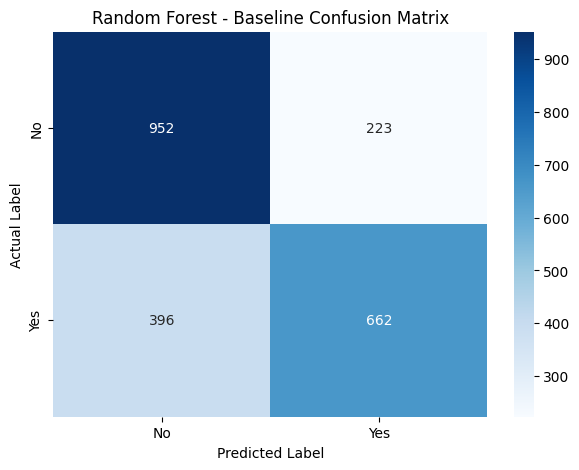

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Random Forest - Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


In [8]:

import os
import pandas as pd

# Create output directory
output_dir = "/kaggle/working/baseline_results"
os.makedirs(output_dir, exist_ok=True)

# Store evaluation metrics
baseline_results = pd.DataFrame({
    'Model': ['Random Forest Baseline'],
    'Accuracy': [baseline_accuracy],
    'Precision': [baseline_precision],
    'Recall': [baseline_recall],
    'F1-Score': [baseline_f1],
    'Training Time': [training_time],
    'Prediction Time': [prediction_time]
})

# Save results
baseline_results.to_csv(
    f"{output_dir}/baseline_metrics.csv",
    index=False
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=['Actual_No', 'Actual_Yes'],
    columns=['Predicted_No', 'Predicted_Yes']
).to_csv(f"{output_dir}/baseline_confusion_matrix.csv")

print("Baseline results saved successfully!")

display(baseline_results)


Baseline results saved successfully!


,Model,Accuracy,Precision,Recall,F1-Score,Training Time,Prediction Time
0,Random Forest Baseline,0.722794,0.748023,0.625709,0.68142,0.832267,0.071302
